# Bài tập Lab 8


## Chuẩn bị
Chạy ô này trước, sau đó chạy các cell theo thứ tự. Nếu CSV ở nơi khác, điền đường dẫn vào các biến `DUONG_DAN_...`. Khi dùng Colab, tải CSV lên theo lời nhắc.

In [1]:
import os, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, mean_absolute_error, silhouette_score, adjusted_rand_score
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import load_digits, load_sample_image
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVC

# Để trống để tìm tự động; có thể chỉ định thư mục dữ liệu ở vị trí khác.
THU_MUC_DATA = os.environ.get("LAB8_DATA_DIR", "")
thu_muc_lab = Path(os.environ.get("LAB8_ROOT", Path.cwd())).resolve()
if "LAB8_ROOT" not in os.environ:
    if thu_muc_lab.name == "code": thu_muc_lab = thu_muc_lab.parent
    elif (thu_muc_lab / "08. K-Means").is_dir(): thu_muc_lab /= "08. K-Means"
thu_muc_hinh = thu_muc_lab / "figures"
thu_muc_hinh.mkdir(parents=True, exist_ok=True)

def tim_dataset(ten_tep):
    if THU_MUC_DATA:
        tep = Path(THU_MUC_DATA).expanduser() / ten_tep
        if tep.is_file(): return tep.resolve()
        raise FileNotFoundError(f"Khong tim thay {ten_tep} trong thu muc du lieu chi dinh.")
    for goc in [thu_muc_lab, Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        for tep in [goc / "08. K-Means" / "data" / ten_tep, goc / "data" / ten_tep, goc / ten_tep]:
            if tep.is_file(): return tep.resolve()
    if "google.colab" in sys.modules:
        from google.colab import files
        print(f"Hay tai len tep {ten_tep}.")
        files.upload()
        if Path(ten_tep).is_file(): return Path(ten_tep).resolve()
    raise FileNotFoundError(f"Can tep {ten_tep}; dat vao data hoac chi dinh THU_MUC_DATA.")

def doc_csv(ten_tep):
    tep = tim_dataset(ten_tep)
    print("Dataset dang su dung:", tep.name)
    return pd.read_csv(tep)

def luu_hinh(ten_tep):
    plt.gcf().tight_layout()
    plt.savefig(thu_muc_hinh / ten_tep, dpi=160, bbox_inches="tight")
    print(f"Da luu hinh: figures/{ten_tep}")
    plt.show()
    plt.close()

def nhan_xet(*cac_cau):
    print("\nNHẬN XÉT VÀ GIẢI THÍCH")
    for cau in cac_cau: print(cau)

# Giữ nội dung cảnh báo hội tụ nhưng không in đường dẫn cài đặt cá nhân.
def canh_bao_ngan(message, category, filename, lineno, file=None, line=None):
    noi_dung = str(message)
    for goc in [thu_muc_lab, Path.home()]:
        for dang in [str(goc), goc.as_posix()]: noi_dung = noi_dung.replace(dang, "<thu_muc>")
    print(f"Canh bao {category.__name__}: {noi_dung}", file=file or sys.stdout)
warnings.showwarning = canh_bao_ngan

def chia_phan_loai(dac_trung, nhan):
    return train_test_split(dac_trung, nhan, test_size=0.25, random_state=17, stratify=nhan)


## Bài 1: Tự tính silhouette

Dataset dang su dung: khach_hang.csv


Silhouette tu tinh: 0.7227055108; thu vien: 0.7227055108
Khach co silhouette nho nhat (chi so bat dau tu 0): 113
tuoi             38.0
thu_nhap         25.4
diem_chi_tieu    41.0
Cum: 2; a=0.917758; b=0.944750; s=0.028571


Da luu hinh: figures/bai1_silhouette.png


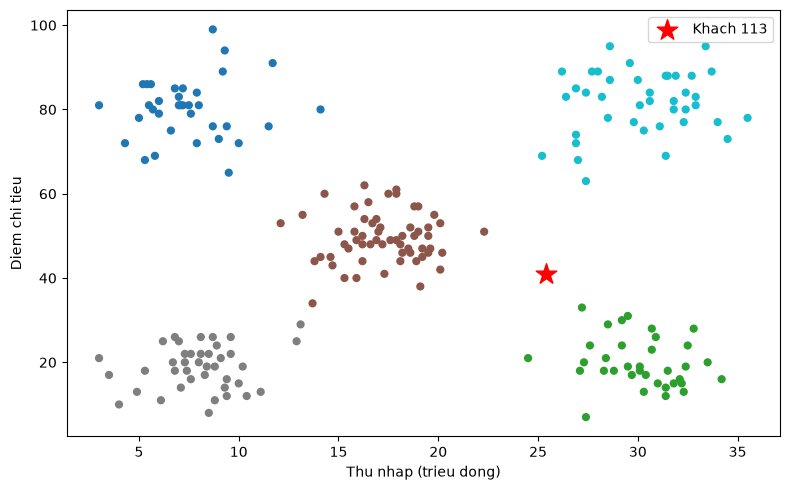


NHẬN XÉT VÀ GIẢI THÍCH
a là khoảng cách Euclid trung bình tới các điểm khác cùng cụm, không tính chính điểm đang xét. b là giá trị nhỏ nhất trong các khoảng cách trung bình tới từng cụm khác; b không phải khoảng cách tới tâm cụm hay tới một điểm gần nhất.
s=(b-a)/max(a,b). s gần 1 thể hiện điểm gắn chặt với cụm; gần 0 cho thấy hai cụm cạnh tranh; s âm cho thấy điểm gần cụm khác hơn theo khoảng cách trung bình. Cụm chỉ có một điểm được quy ước s=0, tương thích scikit-learn.
Trung bình tự tính 0.722706 khớp thư viện. Khách 113 nằm tại thu nhập 25.4, chi tiêu 41.0, được đánh dấu sao trên hình dựng lại cùng hai trục của Hình 3. Đây là khách có mức phân tách kém nhất trong kết quả này, không có nghĩa chắc chắn bị phân cụm sai.


In [2]:
def silhouette_mot_diem(X, nhan, i):
    du_lieu = np.asarray(X, dtype=float)
    cum = np.asarray(nhan)
    if not 1 < len(np.unique(cum)) < len(cum):
        raise ValueError("Can tu 2 den N-1 cum de tinh silhouette.")
    khoang_cach = np.linalg.norm(du_lieu - du_lieu[i], axis=1)
    cung_cum = cum == cum[i]
    cung_cum[i] = False
    a = khoang_cach[cung_cum].mean() if cung_cum.any() else 0.0
    b = min(khoang_cach[cum == ma_cum].mean() for ma_cum in np.unique(cum) if ma_cum != cum[i])
    s = (b-a)/max(a,b) if cung_cum.any() and max(a,b)>0 else 0.0
    return float(a), float(b), float(s)

khach = doc_csv("khach_hang.csv")
dac_trung = StandardScaler().fit_transform(khach[["thu_nhap", "diem_chi_tieu"]])
cum = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(dac_trung)
thong_so = np.array([silhouette_mot_diem(dac_trung,cum,i) for i in range(len(khach))])
sil_tay = thong_so[:,2].mean()
sil_thu_vien = silhouette_score(dac_trung,cum)
print(f"Silhouette tu tinh: {sil_tay:.10f}; thu vien: {sil_thu_vien:.10f}")
assert np.isclose(sil_tay,sil_thu_vien)
vi_tri = int(np.argmin(thong_so[:,2]))
print("Khach co silhouette nho nhat (chi so bat dau tu 0):",vi_tri)
print(khach.iloc[vi_tri].to_string())
print(f"Cum: {cum[vi_tri]}; a={thong_so[vi_tri,0]:.6f}; b={thong_so[vi_tri,1]:.6f}; s={thong_so[vi_tri,2]:.6f}")
plt.figure(figsize=(8,5))
plt.scatter(khach.thu_nhap,khach.diem_chi_tieu,c=cum,cmap="tab10",s=24)
plt.scatter([khach.iloc[vi_tri].thu_nhap],[khach.iloc[vi_tri].diem_chi_tieu],marker="*",s=240,c="red",label=f"Khach {vi_tri}")
plt.xlabel("Thu nhap (trieu dong)"); plt.ylabel("Diem chi tieu"); plt.legend()
luu_hinh("bai1_silhouette.png")
nhan_xet(
 "a là khoảng cách Euclid trung bình tới các điểm khác cùng cụm, không tính chính điểm đang xét. b là giá trị nhỏ nhất trong các khoảng cách trung bình tới từng cụm khác; b không phải khoảng cách tới tâm cụm hay tới một điểm gần nhất.",
 "s=(b-a)/max(a,b). s gần 1 thể hiện điểm gắn chặt với cụm; gần 0 cho thấy hai cụm cạnh tranh; s âm cho thấy điểm gần cụm khác hơn theo khoảng cách trung bình. Cụm chỉ có một điểm được quy ước s=0, tương thích scikit-learn.",
 f"Trung bình tự tính {sil_tay:.6f} khớp thư viện. Khách {vi_tri} nằm tại thu nhập {khach.iloc[vi_tri].thu_nhap:.1f}, chi tiêu {khach.iloc[vi_tri].diem_chi_tieu:.1f}, được đánh dấu sao trên hình dựng lại cùng hai trục của Hình 3. Đây là khách có mức phân tách kém nhất trong kết quả này, không có nghĩa chắc chắn bị phân cụm sai.")


## Bài 2: Thêm cột tuổi

In [3]:
khach=doc_csv("khach_hang.csv")
bo_chuan=StandardScaler().fit(khach[["tuoi","thu_nhap","diem_chi_tieu"]])
dac_trung=bo_chuan.transform(khach[["tuoi","thu_nhap","diem_chi_tieu"]])
cac_mang={}; diem={}
for so_cum in range(2,11):
    mo_hinh=KMeans(n_clusters=so_cum,n_init=10,random_state=0).fit(dac_trung)
    cac_mang[so_cum]=mo_hinh; diem[so_cum]=silhouette_score(dac_trung,mo_hinh.labels_)
    print(f"K={so_cum}: silhouette={diem[so_cum]:.6f}")
so_cum_tot=max(diem,key=diem.get); mo_hinh=cac_mang[so_cum_tot]
tam_moi=pd.DataFrame(bo_chuan.inverse_transform(mo_hinh.cluster_centers_),columns=["tuoi","thu_nhap","diem_chi_tieu"])
tam_moi["so_khach"]=np.bincount(mo_hinh.labels_)
bo_chuan_cu=StandardScaler().fit(khach[["thu_nhap","diem_chi_tieu"]])
mo_hinh_cu=KMeans(n_clusters=5,n_init=10,random_state=0).fit(bo_chuan_cu.transform(khach[["thu_nhap","diem_chi_tieu"]]))
tam_cu=pd.DataFrame(bo_chuan_cu.inverse_transform(mo_hinh_cu.cluster_centers_),columns=["thu_nhap","diem_chi_tieu"])
tam_cu["tuoi"]=khach.assign(cum=mo_hinh_cu.labels_).groupby("cum").tuoi.mean()
print("K tot nhat:",so_cum_tot)
print("Tam cu (don vi goc):\n",tam_cu.sort_values("thu_nhap").round(2).to_string())
print("Tam moi (don vi goc):\n",tam_moi.sort_values("thu_nhap").round(2).to_string())
print("Bang doi chieu cum cu va moi:\n",pd.crosstab(mo_hinh_cu.labels_,mo_hinh.labels_))
nhan_xet(f"K tốt nhất theo silhouette là {so_cum_tot}, "+("vẫn là 5." if so_cum_tot==5 else "khác 5 của mô hình hai đặc trưng."),
 "Bảng tâm đã đổi về đơn vị gốc để đối chiếu thu nhập, chi tiêu và tuổi. Khi tuổi tham gia khoảng cách, những người gần nhau về thu nhập và chi tiêu vẫn có thể bị tách nếu tuổi khác nhau. Bảng chéo cho thấy cụm nào bị tách hoặc gộp; số thứ tự cụm là tùy ý nên không so trực tiếp cụm 0 cũ với cụm 0 mới.",
 "Silhouette ở không gian ba đặc trưng dùng khoảng cách khác không gian hai đặc trưng, nên không coi việc tăng chỉ số giữa hai không gian là bằng chứng chắc chắn phân khúc có ích hơn.")

# Đối chiếu bằng số khách chung để tránh nhầm số thứ tự cụm với danh tính cụm.
bang_chung = pd.crosstab(mo_hinh_cu.labels_, mo_hinh.labels_)
for cum_moi in bang_chung.columns:
    cum_cu = int(bang_chung[cum_moi].idxmax())
    print(f"Cụm mới {cum_moi} có {bang_chung.loc[cum_cu, cum_moi]} khách chung với cụm cũ {cum_cu}. "
          f"So tâm hai cụm này: thu nhập đổi {tam_moi.loc[cum_moi, 'thu_nhap']-tam_cu.loc[cum_cu, 'thu_nhap']:+.2f}, "
          f"chi tiêu đổi {tam_moi.loc[cum_moi, 'diem_chi_tieu']-tam_cu.loc[cum_cu, 'diem_chi_tieu']:+.2f}, "
          f"tuổi đổi {tam_moi.loc[cum_moi, 'tuoi']-tam_cu.loc[cum_cu, 'tuoi']:+.2f}.")
print("Đối chiếu trên chọn cụm cũ có nhiều khách chung nhất cho mỗi cụm mới; không ép ghép một-một khi cụm bị tách hoặc gộp.")


Dataset dang su dung: khach_hang.csv
K=2: silhouette=0.373046
K=3: silhouette=0.422022
K=4: silhouette=0.455826
K=5: silhouette=0.480790
K=6: silhouette=0.476023


K=7: silhouette=0.462742
K=8: silhouette=0.459609


K=9: silhouette=0.462152
K=10: silhouette=0.457308
K tot nhat: 5
Tam cu (don vi goc):
    thu_nhap  diem_chi_tieu   tuoi
0      7.48          80.20  24.94
3      8.04          18.85  44.88
2     17.39          49.30  40.45
1     30.13          19.97  42.86
4     30.21          81.53  32.62
Tam moi (don vi goc):
     tuoi  thu_nhap  diem_chi_tieu  so_khach
0  44.88      8.04          18.85        40
1  25.13      8.48          77.56        39
4  41.65     17.58          49.18        57
2  42.86     30.13          19.97        35
3  32.08     30.28          82.00        39
Bang doi chieu cum cu va moi:
 col_0   0   1   2   3   4
row_0                    
0       0  35   0   0   0
1       0   0  35   0   0
2       0   4   0   0  56
3      40   0   0   0   0
4       0   0   0  39   1

NHẬN XÉT VÀ GIẢI THÍCH
K tốt nhất theo silhouette là 5, vẫn là 5.
Bảng tâm đã đổi về đơn vị gốc để đối chiếu thu nhập, chi tiêu và tuổi. Khi tuổi tham gia khoảng cách, những người gần nhau về thu nhập và chi 

## Bài 3: K-Means++ và khởi tạo ngẫu nhiên

In [4]:
khach=doc_csv("khach_hang.csv")
dac_trung=StandardScaler().fit_transform(khach[["thu_nhap","diem_chi_tieu"]])
ket_qua={}
for khoi_tao in ["random","k-means++"]:
    inertia=np.array([KMeans(n_clusters=5,init=khoi_tao,n_init=1,random_state=hat).fit(dac_trung).inertia_ for hat in range(50)])
    ket_qua[khoi_tao]=inertia
    so_dat=int(np.sum(np.round(inertia,1)==23.0))
    print(f"{khoi_tao}: dat 23.0 = {so_dat}/50; min={inertia.min():.6f}; max={inertia.max():.6f}; trung binh={inertia.mean():.6f}")
    print("Inertia 50 lan:",np.round(inertia,1))
dem={ten:int(np.sum(np.round(gia_tri,1)==23.0)) for ten,gia_tri in ket_qua.items()}
tot=[ten for ten in dem if dem[ten]==max(dem.values())]
nhan_xet(f"Trong 50 seed đã thử, {', '.join(tot)} đạt mốc 23,0 nhiều nhất ({max(dem.values())}/50 lần). Nếu hai cách bằng nhau, thí nghiệm này chưa cho thấy cách nào đáng tin hơn theo tiêu chí đó.",
 "23,0 trong tài liệu là số làm tròn một chữ số; vì vậy đếm sau khi làm tròn inertia một chữ số, không kiểm tra bằng đúng số thực 23.0. Inertia là tổng bình phương khoảng cách tới tâm; thấp hơn nghĩa là nghiệm tốt hơn trên cùng dữ liệu và K.",
 "K-Means có thể dừng ở cực tiểu cục bộ tùy tâm ban đầu. Khởi tạo ngẫu nhiên có thể đặt nhiều tâm vào cùng vùng; k-means++ chọn tâm tiếp theo với xác suất tỷ lệ bình phương khoảng cách tới tâm gần nhất, giúp trải tâm ra nhưng không bảo đảm tối ưu toàn cục.",
 "n_init=1 cố ý làm lộ ảnh hưởng của một lần khởi tạo. Khi dùng thực tế, n_init lớn chạy nhiều khởi tạo và giữ nghiệm inertia thấp nhất; random_state giúp tái lập, không tự bảo đảm nghiệm tốt.")


Dataset dang su dung: khach_hang.csv


random: dat 23.0 = 30/50; min=23.016749; max=204.045584; trung binh=53.291388
Inertia 50 lan: [ 23.   23.   23.   84.2  23.   23.   23.   73.6 116.6  73.7  72.4  84.2
  73.7  23.   84.  118.2  23.  117.4  23.   23.  119.3  23.   23.   23.
  23.   23.   23.   23.  204.   23.   84.1  23.   23.   84.1  72.4  23.
  23.   23.   23.   23.   23.  116.6  23.   73.3  23.  118.2 119.3  23.
  23.   84.9]


k-means++: dat 23.0 = 50/50; min=23.016749; max=23.016749; trung binh=23.016749
Inertia 50 lan: [23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23.
 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23.
 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23.]

NHẬN XÉT VÀ GIẢI THÍCH
Trong 50 seed đã thử, k-means++ đạt mốc 23,0 nhiều nhất (50/50 lần). Nếu hai cách bằng nhau, thí nghiệm này chưa cho thấy cách nào đáng tin hơn theo tiêu chí đó.
23,0 trong tài liệu là số làm tròn một chữ số; vì vậy đếm sau khi làm tròn inertia một chữ số, không kiểm tra bằng đúng số thực 23.0. Inertia là tổng bình phương khoảng cách tới tâm; thấp hơn nghĩa là nghiệm tốt hơn trên cùng dữ liệu và K.
K-Means có thể dừng ở cực tiểu cục bộ tùy tâm ban đầu. Khởi tạo ngẫu nhiên có thể đặt nhiều tâm vào cùng vùng; k-means++ chọn tâm tiếp theo với xác suất tỷ lệ bình phương khoảng cách tới tâm gần nhất, giúp trải tâm ra nhưng không bảo đảm tối ưu toàn cục.
n_init=1 cố ý làm l

## Bài 4: Lưu ảnh đã nén
Dùng ảnh mẫu và ảnh cá nhân `dohoangphuc3x4.jpg`.

In [5]:
def nen_va_luu(anh, tien_to):
    anh=np.asarray(anh)
    if anh.ndim==2: anh=np.repeat(anh[:,:,None],3,axis=2)
    if anh.ndim!=3 or anh.shape[2]<3: raise ValueError("Anh can cac kenh RGB.")
    anh=anh[:,:,:3]  # Bỏ alpha nếu là PNG RGBA.
    if np.issubdtype(anh.dtype,np.integer): anh=anh.astype(float)/np.iinfo(anh.dtype).max
    else: anh=anh.astype(float)
    anh=np.clip(anh,0,1)
    diem=anh.reshape(-1,3)
    rng=np.random.default_rng(0)
    mau=diem[rng.choice(len(diem),min(5000,len(diem)),replace=False)]
    mang=KMeans(n_clusters=16,n_init=4,random_state=0).fit(mau)
    anh_moi=mang.cluster_centers_[mang.predict(diem)].reshape(anh.shape)
    ten_goc=f"{tien_to}_goc.png"; ten_moi=f"{tien_to}_16_mau.png"
    plt.imsave(thu_muc_hinh/ten_goc,anh)
    plt.imsave(thu_muc_hinh/ten_moi,anh_moi)
    for ten in [ten_goc,ten_moi]: print(f"Da luu hinh: figures/{ten}")
    dung_luong_goc=(thu_muc_hinh/ten_goc).stat().st_size
    dung_luong_moi=(thu_muc_hinh/ten_moi).stat().st_size
    print(f"{tien_to}: kich thuoc={anh_moi.shape}; goc={dung_luong_goc} byte; 16 mau={dung_luong_moi} byte; ty so={dung_luong_goc/dung_luong_moi:.3f}")
    return dung_luong_goc,dung_luong_moi

thong_ke_mau=nen_va_luu(load_sample_image("china.jpg"),"anh")
anh_ca_nhan=plt.imread(tim_dataset("dohoangphuc3x4.jpg"))
thong_ke_ca_nhan=nen_va_luu(anh_ca_nhan,"dohoangphuc3x4")
nhan_xet(f"Ảnh mẫu sau nén còn {thong_ke_mau[1]} byte so với {thong_ke_mau[0]} byte của PNG gốc; ảnh cá nhân còn {thong_ke_ca_nhan[1]} byte so với {thong_ke_ca_nhan[0]} byte.",
 "Cả hai bản trước và sau đều được lưu PNG để so cùng định dạng. Kết quả dung lượng được đo từ tệp thật; không mặc định ảnh 16 màu nhỏ đúng 6 lần. Con số 6 trong phần thực hành là tỷ lệ lý tưởng 24 bit/4 bit khi biểu diễn chỉ số bảng màu, chưa kể bảng màu và phần đầu tệp.",
 "plt.imsave lưu PNG RGB/RGBA chứ không tự bảo đảm dùng bảng màu 4 bit. Kích thước tệp còn phụ thuộc bộ nén và cấu trúc ảnh. Bỏ kênh alpha nghĩa là mất thông tin trong suốt; đây là xử lý theo yêu cầu đề. Mô hình học trên tối đa 5.000 pixel rồi dự đoán mọi pixel để giảm thời gian.")


Da luu hinh: figures/anh_goc.png
Da luu hinh: figures/anh_16_mau.png
anh: kich thuoc=(427, 640, 3); goc=550154 byte; 16 mau=134431 byte; ty so=4.092


Da luu hinh: figures/dohoangphuc3x4_goc.png
Da luu hinh: figures/dohoangphuc3x4_16_mau.png
dohoangphuc3x4: kich thuoc=(975, 735, 3); goc=297299 byte; 16 mau=63164 byte; ty so=4.707

NHẬN XÉT VÀ GIẢI THÍCH
Ảnh mẫu sau nén còn 134431 byte so với 550154 byte của PNG gốc; ảnh cá nhân còn 63164 byte so với 297299 byte.
Cả hai bản trước và sau đều được lưu PNG để so cùng định dạng. Kết quả dung lượng được đo từ tệp thật; không mặc định ảnh 16 màu nhỏ đúng 6 lần. Con số 6 trong phần thực hành là tỷ lệ lý tưởng 24 bit/4 bit khi biểu diễn chỉ số bảng màu, chưa kể bảng màu và phần đầu tệp.
plt.imsave lưu PNG RGB/RGBA chứ không tự bảo đảm dùng bảng màu 4 bit. Kích thước tệp còn phụ thuộc bộ nén và cấu trúc ảnh. Bỏ kênh alpha nghĩa là mất thông tin trong suốt; đây là xử lý theo yêu cầu đề. Mô hình học trên tối đa 5.000 pixel rồi dự đoán mọi pixel để giảm thời gian.


## Bài 5: DBSCAN trên hai vầng trăng

Dataset dang su dung: hai_vang_trang.csv
eps=0.2: so cum=1; nhieu=40; ARI=-0.0014
eps=0.3: so cum=1; nhieu=10; ARI=0.0012
eps=0.4: so cum=1; nhieu=3; ARI=-0.0001
K-Means: ARI=0.2475


Da luu hinh: figures/bai5_dbscan.png


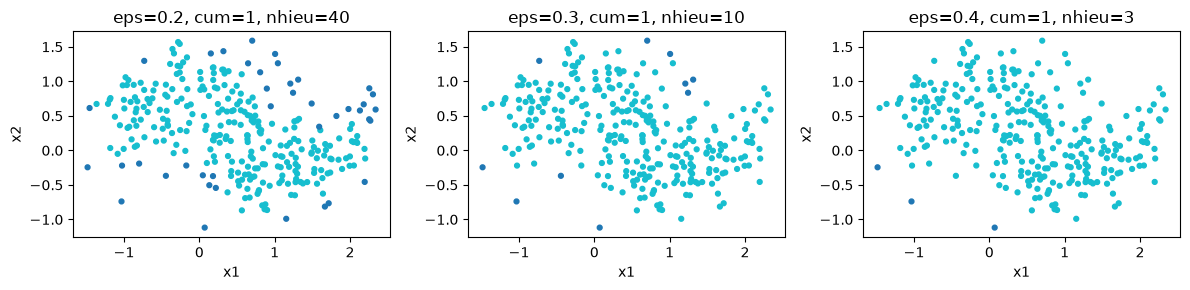


NHẬN XÉT VÀ GIẢI THÍCH
Các eps có ARI cao hơn K-Means trên dữ liệu này: []. ARI so với nhãn thật không phụ thuộc việc hoán đổi số thứ tự cụm; nhãn chỉ dùng để đánh giá sau phân cụm. ARI ở đây tính trên toàn bộ mẫu, kể cả nhóm nhãn -1.
eps nhỏ làm vùng lân cận hẹp, dễ tách thành nhiều cụm hoặc đánh dấu nhiễu; eps lớn có thể nối hai vầng trăng thành một cụm. DBSCAN có thể theo hình cong nhờ mật độ, còn K-Means gán theo tâm gần nhất nên thường cắt ngang hai vầng trăng. Phải xem cả hình, số cụm và số điểm nhiễu khi kết luận.


In [6]:
trang=doc_csv("hai_vang_trang.csv"); dac_trung=trang[["x1","x2"]]
cum_kmeans=KMeans(n_clusters=2,n_init=10,random_state=0).fit_predict(dac_trung)
ari_kmeans=adjusted_rand_score(trang.nhan,cum_kmeans)
diem_db={}
plt.figure(figsize=(12,3))
for vi_tri,eps in enumerate([0.2,0.3,0.4],1):
    cum=DBSCAN(eps=eps,min_samples=5).fit_predict(dac_trung)
    so_cum=len(set(cum)-{-1}); so_nhieu=int(np.sum(cum==-1))
    diem_db[eps]=adjusted_rand_score(trang.nhan,cum)
    print(f"eps={eps}: so cum={so_cum}; nhieu={so_nhieu}; ARI={diem_db[eps]:.4f}")
    plt.subplot(1,3,vi_tri); plt.scatter(trang.x1,trang.x2,c=cum,cmap="tab10",s=12)
    plt.title(f"eps={eps}, cum={so_cum}, nhieu={so_nhieu}"); plt.xlabel("x1"); plt.ylabel("x2")
print(f"K-Means: ARI={ari_kmeans:.4f}")
luu_hinh("bai5_dbscan.png")
tot_hon=[eps for eps,diem in diem_db.items() if diem>ari_kmeans]
nhan_xet(f"Các eps có ARI cao hơn K-Means trên dữ liệu này: {tot_hon}. ARI so với nhãn thật không phụ thuộc việc hoán đổi số thứ tự cụm; nhãn chỉ dùng để đánh giá sau phân cụm. ARI ở đây tính trên toàn bộ mẫu, kể cả nhóm nhãn -1.",
 "eps nhỏ làm vùng lân cận hẹp, dễ tách thành nhiều cụm hoặc đánh dấu nhiễu; eps lớn có thể nối hai vầng trăng thành một cụm. DBSCAN có thể theo hình cong nhờ mật độ, còn K-Means gán theo tâm gần nhất nên thường cắt ngang hai vầng trăng. Phải xem cả hình, số cụm và số điểm nhiễu khi kết luận.")


## Bài 6: Phân cụm chữ số viết tay

In [7]:
anh,nhan_that=load_digits(return_X_y=True)
# Không đưa nhãn thật vào fit.
cum=KMeans(n_clusters=10,n_init=10,random_state=0).fit_predict(anh)
bang=pd.crosstab(pd.Series(nhan_that,name="Chu so that"),pd.Series(cum,name="Cum"))
print(bang.to_string())
ty_le=bang.max(axis=1)/bang.sum(axis=1)
print("\nTy le gom vao cum dong nhat cua tung chu so:")
print(ty_le.round(4).to_string())
gon=ty_le.index[np.isclose(ty_le,ty_le.max())].tolist()
nhan_xet(f"Chữ số được gom gọn nhất theo tỷ lệ vào cụm đông nhất là {gon}, đạt {ty_le.max():.2%}. Đây là mức tập trung, không phải accuracy phân loại.",
 "Mỗi cột là một cụm, mỗi hàng là chữ số thật. Số thứ tự cụm không phải nhãn chữ số. Các cặp dưới đây mô tả hai chữ số đông nhất trong từng cụm, kèm số lượng để thấy mức trộn; một chữ số cũng có thể bị chia thành nhiều cụm.")
for ma_cum in bang.columns:
    dong=bang[ma_cum].sort_values(ascending=False)
    print(f"Cụm {ma_cum}: chữ số {dong.index[0]} có {dong.iloc[0]} ảnh; chữ số {dong.index[1]} có {dong.iloc[1]} ảnh, tổng {dong.sum()} ảnh.")


Cum            0    1    2   3    4    5    6    7    8    9
Chu so that                                                 
0            176    0    0   0    0    0    2    0    0    0
1              0  100    0  54    1    2    0    1    0   24
2              1    8    3   2   13    0    0    0    2  148
3              0    7    7   0  154    0    0    2   13    0
4              0    2   11   3    0    0  165    0    0    0
5              0    0    0   0    2    1    2  136   41    0
6              1    3    0   0    0  177    0    0    0    0
7              0    2  174   2    0    0    0    1    0    0
8              0  100    5   6    2    2    0    4   52    3
9              0    1    8  20    6    0    0    6  139    0

Ty le gom vao cum dong nhat cua tung chu so:
Chu so that
0    0.9888
1    0.5495
2    0.8362
3    0.8415
4    0.9116
5    0.7473
6    0.9779
7    0.9721
8    0.5747
9    0.7722

NHẬN XÉT VÀ GIẢI THÍCH
Chữ số được gom gọn nhất theo tỷ lệ vào cụm đông nhất là [0], đạt 